<a href="https://colab.research.google.com/github/kalpakjian/ivdc_handout/blob/main/colab/ivdc_exam_quickstart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IVDC Lesson 8 · Colab 考試速用本

**三條規則**

1. **Colab 沒有 webcam、也沒有螢幕** → 任何 `cv2.VideoCapture(0)` / `cv2.imshow()` 都會失敗。
   本 repo 的腳本已經處理好：`imshow` 自動退回存檔、`--video 檔案.mp4` 可以取代攝影機。
2. **不用自己裝 TF / torch / cv2** —— Colab 2026.10 內建 TF 2.21.0、torch 2.11.0+cpu、
   torchvision 0.26.0+cpu、opencv 5.0.0、tensorflow-hub 0.16.1。只差 `ultralytics`（YOLO）。
3. **`setuptools` 不用降版** —— Colab 是 80.10.2（< 81），`pkg_resources` 還在，
   `tensorflow_hub` 直接可以 import。（在自己電腦上才需要 `setuptools<81`。）

執行順序：往下依序跑，每格都印出可貼進答案的輸出。

## 1. 取得程式碼

In [2]:
import os
if not os.path.isdir("ivdc_handout"):
    !git clone -q https://github.com/kalpakjian/ivdc_handout
%cd ivdc_handout
import os; print(sorted(os.listdir("src"))); print(os.listdir("bench"))

/content/ivdc_handout
['00_check_env.py', '01_tf_object_detection_image.py', '02_tf_webcam_detection.py', '03_torch_object_detection_image.py', '04_torch_webcam_detection.py', '05_yolo_detection.py', '06_tf_cnn_mnist.py', '07_torch_cnn_mnist.py']
['bench_detection.py']


## 2. 環境自檢（先跑這格，出問題就不要往下）

In [3]:
import sys, importlib, platform
print(platform.platform(), "| Python", sys.version.split()[0])
for m in ["numpy", "cv2", "torch", "torchvision", "tensorflow", "tensorflow_hub", "matplotlib", "ultralytics"]:
    try:
        mod = importlib.import_module(m)
        print(f"  OK      {m:16s} {getattr(mod, '__version__', '?')}")
    except Exception:
        print(f"  MISSING {m:16s}")
import torch
print("CUDA:", torch.cuda.is_available(), "|", (torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"))
print("\n-- 本 repo 的完整自檢（Colab 沒有相機，所以跳過）--")
%run src/00_check_env.py --skip-camera

Linux-6.6.159+-x86_64-with-glibc2.39 | Python 3.13.16
  OK      numpy            2.4.6
  OK      cv2              4.14.0
  OK      torch            2.11.0+cu130
  OK      torchvision      0.26.0+cu130
  OK      tensorflow       2.21.0


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


  OK      tensorflow_hub   0.16.1
  OK      matplotlib       3.10.0
  MISSING ultralytics     
CUDA: True | Tesla T4

-- 本 repo 的完整自檢（Colab 沒有相機，所以跳過）--
== 平台 ==
  Linux-6.6.159+-x86_64-with-glibc2.39

== 套件 ==
  OK      cv2              4.14.0
  OK      torch            2.11.0+cu130
  OK      torchvision      0.26.0+cu130
  OK      tensorflow       2.21.0
  OK      tensorflow_hub   0.16.1
  MISSING ultralytics      -> pip install ultralytics
  OK      numpy            2.4.6
  OK      matplotlib       3.10.0
  --      python           3.13.16 (/usr/bin/python3)

== 顯示 (GUI) ==
  UI 框架: QT
  失敗    imshow 不可用（headless 版 OpenCV）
  修法:    pip uninstall opencv-python-headless -y && pip install opencv-python

== 結論 ==
  可用推論框架: torch, tensorflow
  GUI: 沒有，請走存檔模式
  相機: 未檢查（--skip-camera）


## 3. 補裝 ultralytics（只有 YOLO 那格需要）

In [4]:
%pip install -q ultralytics
import ultralytics
print("ultralytics", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.202


## 4. 測試素材（Colab 沒有你的圖，先抓官方的）

In [5]:
import urllib.request
urllib.request.urlretrieve("https://ultralytics.com/images/bus.jpg", "bus.jpg")
import os
print("bus.jpg", os.path.getsize("bus.jpg"), "bytes")

bus.jpg 137419 bytes


## 5. 物件偵測 · 單張圖（torchvision，簡報第 5 頁）

注意這是 **CPU** 的 torch；要 1.1 FPS 那個對照組就跑 `--model fasterrcnn_resnet50_fpn`。

In [6]:
%run src/03_torch_object_detection_image.py --image bus.jpg --model ssdlite320 --threshold 0.4

PyTorch 2.11.0+cu130 / torchvision 0.26.0+cu130
Downloading: "https://download.pytorch.org/models/ssdlite320_mobilenet_v3_large_coco-a79551df.pth" to /root/.cache/torch/hub/checkpoints/ssdlite320_mobilenet_v3_large_coco-a79551df.pth


100%|██████████| 13.4M/13.4M [00:00<00:00, 69.6MB/s]


模型: ssdlite320_mobilenet_v3_large

檢出（門檻 0.4）:
  person           score=0.989 box=(48, 390, 224, 899) 絕對像素
  bus              score=0.985 box=(22, 238, 802, 755) 絕對像素
  person           score=0.865 box=(221, 402, 334, 859) 絕對像素
  person           score=0.624 box=(676, 324, 806, 872) 絕對像素
共 4 個
已存檔: out/torch_detection.jpg


## 6. 物件偵測 · YOLOv8（簡報第 7 頁的四行方案）

In [7]:
%run src/05_yolo_detection.py --source bus.jpg --imgsz 640

model=yolov8n.pt source=bus.jpg imgsz=640 conf=0.25
frame 0001: 6 個物件, 最高信心 0.87, 推論 12.0 ms (83.6 FPS)

已存 1 張到 out/yolo/


## 7. 物件偵測 · TensorFlow / TF-Hub（簡報第 2 頁）

In [8]:
%run src/01_tf_object_detection_image.py --image bus.jpg --threshold 0.5

Python 3.13.16 / TF 2.21.0
模型: https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2

檢出 5 個（門檻 0.5）
  person           score=0.861 box=(0.047, 0.369, 0.274, 0.817) 歸一化
  bus              score=0.756 box=(0.015, 0.218, 1.000, 0.717) 歸一化
  person           score=0.750 box=(0.253, 0.378, 0.430, 0.793) 歸一化
  person           score=0.602 box=(0.849, 0.333, 1.000, 0.814) 歸一化
  person           score=0.517 box=(0.089, 0.379, 0.342, 0.845) 歸一化

已存檔: out/tf_detection.jpg


## 8. 「即時偵測」在 Colab 怎麼辦（簡報第 3／6 頁）

**沒有 webcam**，所以把攝影機換成影片檔，流程一行都不用改。考試時如果題目要求即時偵測，
就自己產一段影片（下面用 webcam 影格合成不行時，直接拿 bus.jpg 做成 2 秒短片）：

```python
# 沒有 webcam 時，用一張圖合成一段影片當來源
import cv2
img = cv2.imread("bus.jpg")
w = cv2.VideoWriter("clip.mp4", cv2.VideoWriter_fourcc(*"mp4v"), 15.0, (img.shape[1], img.shape[0]))
for _ in range(30):
    w.write(img)
w.release()
```

In [9]:
import cv2
img = cv2.imread("bus.jpg")
w = cv2.VideoWriter("clip.mp4", cv2.VideoWriter_fourcc(*"mp4v"), 15.0, (img.shape[1], img.shape[0]))
for _ in range(30):
    w.write(img)
w.release()
%run src/04_torch_webcam_detection.py --video clip.mp4 --model ssdlite320

PyTorch 2.11.0+cu130 / torchvision 0.26.0+cu130
模型: ssdlite320_mobilenet_v3_large
來源: 影片 clip.mp4（30 幀）
[提醒] 沒有 GUI backend，改成存圖到 out/webcam_torch/
影片播完
已存 30 張到 out/webcam_torch/
平均速度: 9.4 FPS（30 幀）


## 9. CNN 分類（簡報第 8–25 頁）· 考試時間短，用 1–2 epochs

In [10]:
%run src/06_tf_cnn_mnist.py --epochs 1 --no-plot

Python 3.13.16 / TF 2.21.0 / Keras 3.13.2
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training Data Shape: (60000, 28, 28)
Test Data Shape: (10000, 28, 28)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Param count: 225,034
1688/1688 - 16s - 10ms/step - accuracy: 0.9562 - loss: 0.1424 - val_accuracy: 0.9878 - val_loss: 0.0493

Test loss: 0.0517
Test accuracy: 0.9828
Predicted Class: 7
Actual Class: 7


In [11]:
%run src/07_torch_cnn_mnist.py --epochs 1

PyTorch 2.11.0+cu130 / torchvision 0.26.0+cu130


100%|██████████| 9.91M/9.91M [00:00<00:00, 11.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 330kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.31MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.32MB/s]


Training samples: 60000
Test samples: 10000
Image shape: torch.Size([1, 28, 28])
Net(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Param count: 225,034
Epoch 1/1, Loss: 0.1695
Test accuracy: 0.9806 (9806/10000)
Predicted Class: 7
Actual Class: 7


## 10. 看結果圖（Colab 沒有視窗，用 display 把存下來的標註圖貼出來）

out/torch_detection.jpg


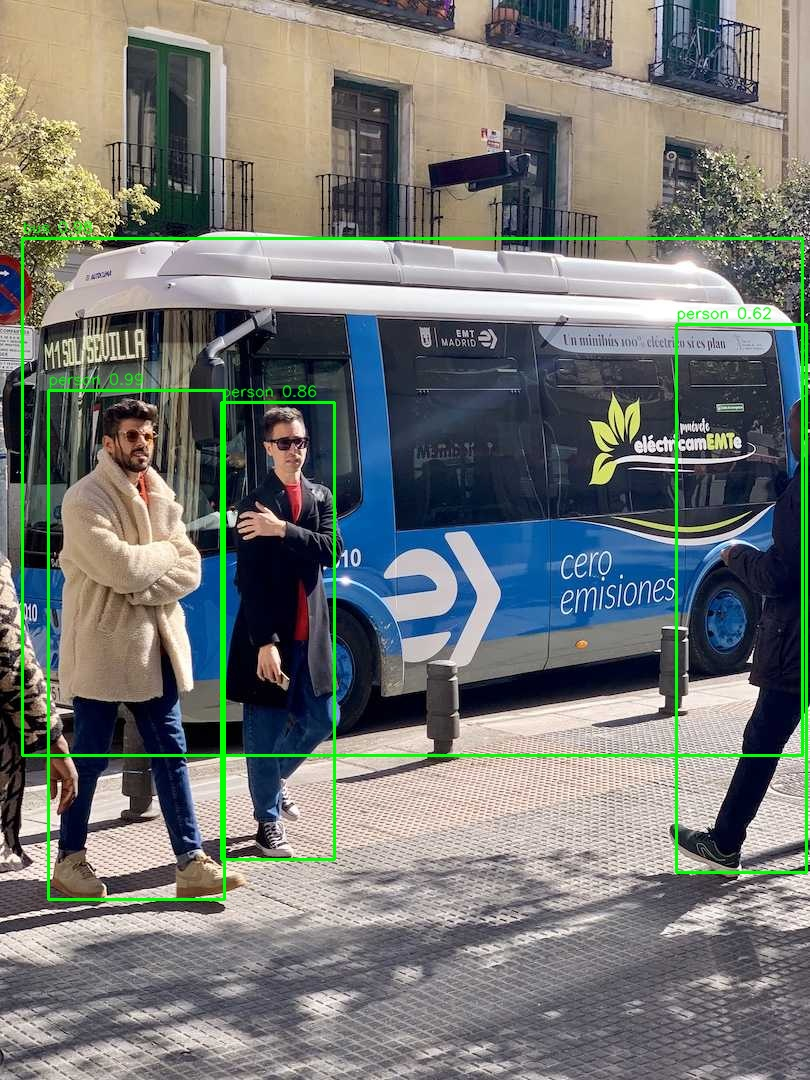

out/tf_detection.jpg


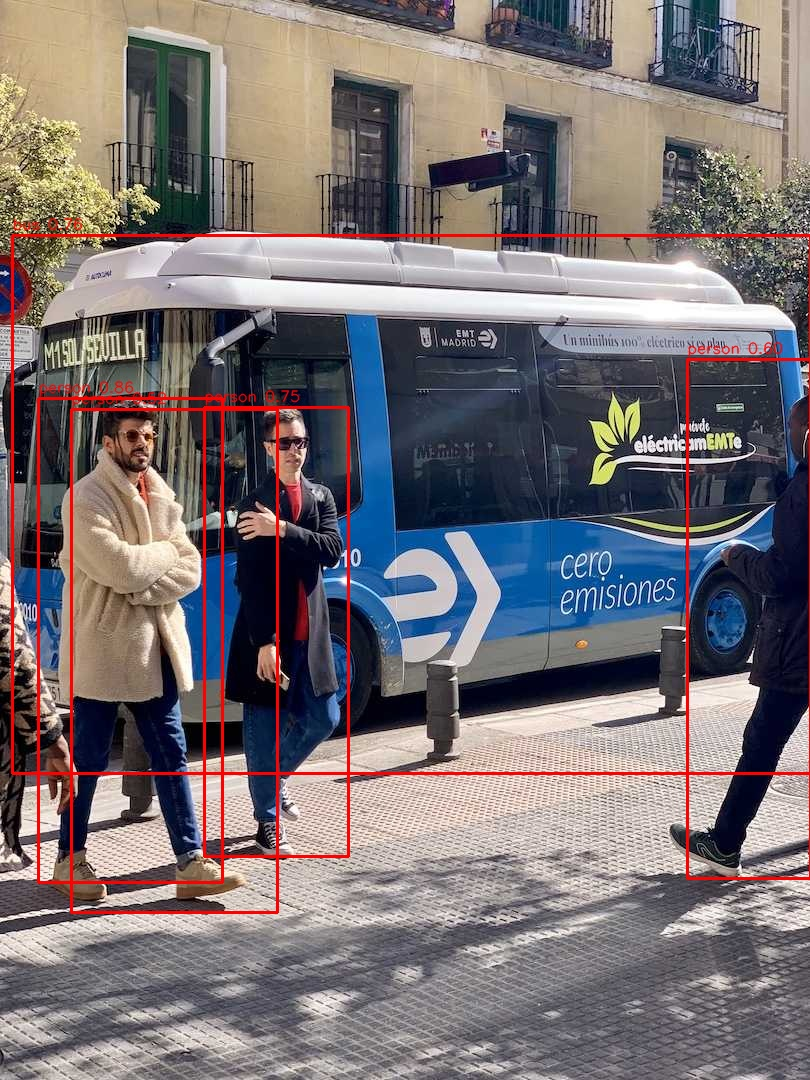

out/yolo/pred_0000.jpg


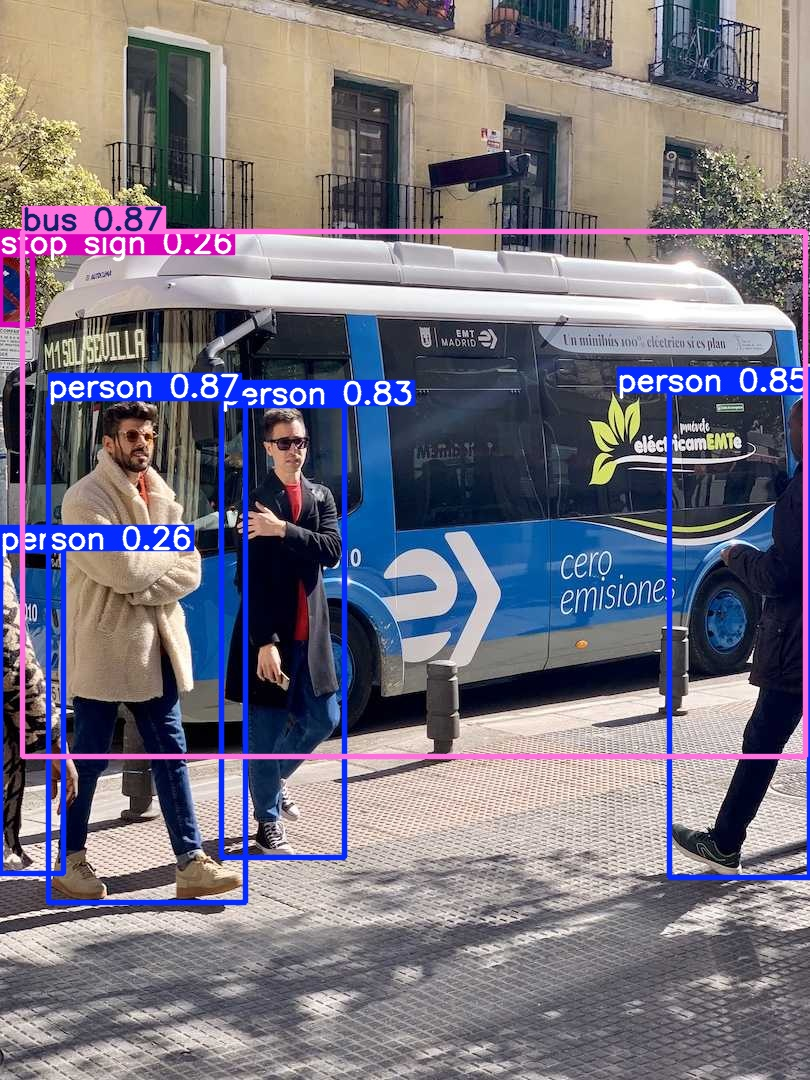

In [12]:
from IPython.display import Image, display
import glob
for p in ["out/torch_detection.jpg", "out/tf_detection.jpg"] + sorted(glob.glob("out/yolo/*.jpg"))[:1]:
    if glob.glob(p):
        print(p); display(Image(p, width=640))

## 考試當天速查：錯誤 → 解法

| 症狀 | 原因 | 解法 |
|---|---|---|
| `cv2.error: ... not implemented ... GTK+ 2.x` | Colab 沒有 GUI backend | 不要 `imshow`；用 `--no-show`，圖存在 `out/`，用 `display(Image(...))` 看 |
| `[錯誤] 找不到有畫面的攝影機` | Colab 沒有 webcam | 用 `--video clip.mp4`（第 8 格） |
| `ModuleNotFoundError: ultralytics` | 沒預裝 | 第 3 格 `%pip install -q ultralytics` |
| `ModuleNotFoundError: No module named 'pkg_resources'` | 只有**自己電腦**的 setuptools ≥ 81 才會；Colab 不會 | 本機：`pip install 'setuptools<81'` |
| TF-Hub `hub.load` 很慢 / 卡住 | 第一次要下載 ~20 MB | 等它；或改用 torchvision 那條線 |
| MNIST 下載失敗 | 短暫網路問題 | 重跑該格（Keras 會重試） |
| `Runtime disconnected` | 閒置 | 考前把筆記本開著，別關分頁 |
| 想用 GPU 但只有 CPU 版 torch | 執行環境選錯 | 右上「執行環境 → 變更執行環境 → T4 GPU」 |

**貼答案要用的數字**：`03` 會印 `person 0.989 / bus 0.985`；`05` 印 `6 個物件、最高 0.87`；
`06`／`07` 印 `Test accuracy`。這些在 CPU 上分別約 30 ms、28 ms、20 秒／epoch。